<div dir="rtl">

# אופטימיזציה בתורים בעזרת סימולציה

### בשיעור הזה החלטת האיוש כוללת שני סוגי שרתים:

### - **שרתים איטיים**: זולים יותר, אבל זמן השירות הממוצע שלהם ארוך יותר.
### - **שרתים מהירים**: יקרים יותר, אבל מסיימים שירות מהר יותר.

### השאלה היא לא רק *כמה שרתים* להפעיל. השאלה היא:

### > כמה שרתים איטיים וכמה שרתים מהירים כדאי להפעיל?

### לקוחות מגיעים בקצב הגעה ממוצע קבוע. אם לקוח ממתין יותר מזמן הסבלנות האקראי שלו `R`, הוא נוטש את המערכת. שרתים עולים כסף ליחידת זמן, ולקוחות נוטשים יוצרים קנס או הפסד.

<div dir="rtl">

## מודל העלות

### עבור תמהיל עם `f` שרתים מהירים ו-`s` שרתים איטיים, הסימולציה מעריכה שני מדדים מרכזיים.

### קצב תפוקה, כלומר מספר הלקוחות שקיבלו שירות ליחידת זמן:

### $$T(f,s) = \frac{N_{served}}{H}$$

### קצב נטישה, כלומר מספר הלקוחות שנטשו ליחידת זמן:

### $$A(f,s) = \frac{N_{abandoned}}{H}$$

### כאשר `H` הוא אופק הזמן של הסימולציה.

### פונקציית המטרה הכלכלית היא:

### $$C(f,s) = f \cdot C_F + s \cdot C_S + C_A \cdot A(f,s)$$

### כאשר `C_F` היא עלות שרת מהיר ליחידת זמן, `C_S` היא עלות שרת איטי ליחידת זמן, ו-`C_A` היא עלות נטישה של לקוח.

### מערכת שמורכבת רק משרתים איטיים היא זולה, אבל עלולה לאבד הרבה לקוחות. מערכת שמורכבת רק משרתים מהירים נותנת שירות טוב, אבל יכולה להיות יקרה מדי. אנחנו מחפשים תמהיל מאוזן באמצע.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append('../../code')

from utils import (
    simulate_multiserver_queue_with_abandonment_from_times,
    evaluate_two_server_type_grid_with_abandonment,
    results_to_dataframe,
)

plt.style.use('seaborn-v0_8-whitegrid')

<div dir="rtl">

## יצירת קלטים אקראיים משותפים

### הקלטים לסימולציה הם מימושים אקראיים, לא רק נוסחאות:

### - `inter_arrival_times[i]` - הזמן בין ההגעה של לקוח `i` להגעה הקודמת.
### - `slow_service_times[i, j]` - זמן השירות של לקוח `i` אם הוא מטופל על ידי שרת איטי `j`.
### - `fast_service_times[i, j]` - זמן השירות של לקוח `i` אם הוא מטופל על ידי שרת מהיר `j`.
### - `patience_times[i]` - זמן הסבלנות של לקוח `i`.

### נשתמש באותם מימושים אקראיים עבור כל תמהיל שרתים. כך ההשוואה בין החלופות נקייה יותר, כי כל חלופה מתמודדת עם אותו זרם הגעות ואותם זמני סבלנות.

In [8]:
rng = np.random.default_rng(2026)

NUM_CUSTOMERS = 800_000
ARRIVAL_RATE = 8.0  # customers per hour

MAX_SLOW_SERVERS = 7
MAX_FAST_SERVERS = 5
MAX_TOTAL_SERVERS = 7

SLOW_SERVICE_RATE = 1.5  # mean service time = 40 minutes
FAST_SERVICE_RATE = 3.5  # mean service time is about 17 minutes

SLOW_SERVER_COST_RATE = 30.0
FAST_SERVER_COST_RATE = 55.0
ABANDONMENT_PENALTY = 200.0

inter_arrival_times = rng.exponential(scale=1 / ARRIVAL_RATE, size=NUM_CUSTOMERS)
slow_service_times = rng.exponential(
    scale=1 / SLOW_SERVICE_RATE,
    size=(NUM_CUSTOMERS, MAX_SLOW_SERVERS),
)
fast_service_times = rng.exponential(
    scale=1 / FAST_SERVICE_RATE,
    size=(NUM_CUSTOMERS, MAX_FAST_SERVERS),
)

# Mean patience is shape * scale = 0.16 hours = 9.6 minutes.
patience_times = rng.gamma(shape=2.0, scale=0.08, size=NUM_CUSTOMERS)

print(f"Empirical arrival rate: {NUM_CUSTOMERS / inter_arrival_times.sum():.2f} customers/hour")
print(f"Mean patience: {patience_times.mean() * 60:.1f} minutes")
print(f"Mean slow-service time: {slow_service_times.mean() * 60:.1f} minutes")
print(f"Mean fast-service time: {fast_service_times.mean() * 60:.1f} minutes")

Empirical arrival rate: 8.02 customers/hour
Mean patience: 9.6 minutes
Mean slow-service time: 40.0 minutes
Mean fast-service time: 17.1 minutes


<div dir="rtl">

## קודם נסמלץ תמהיל אחד

### לפני האופטימיזציה, נסתכל על מערכת אפשרית אחת: `2` שרתים מהירים ו-`4` שרתים איטיים.

### בפונקציית הסימולציה, העמודות של השרתים המהירים הפעילים מופיעות לפני העמודות של השרתים האיטיים הפעילים. לכן, עם כלל ההשמה ברירת המחדל, אם יש גם שרת מהיר פנוי וגם שרת איטי פנוי, הלקוח יופנה קודם לשרת המהיר.

In [9]:
example_fast_servers = 2
example_slow_servers = 4

example_service_times = np.column_stack([
    fast_service_times[:, :example_fast_servers],
    slow_service_times[:, :example_slow_servers],
])

example_result = simulate_multiserver_queue_with_abandonment_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=example_service_times,
    patience_times=patience_times,
    server_count=example_fast_servers + example_slow_servers,
    assignment_rule='first_available',
)

for key in [
    'num_arrivals',
    'num_served',
    'num_abandoned',
    'fraction_abandoned',
    'throughput_rate',
    'abandonment_rate',
    'mean_waiting_time_served',
]:
    print(f"{key}: {example_result[key]}")

num_arrivals: 800000
num_served: 762418
num_abandoned: 37582
fraction_abandoned: 0.0469775
throughput_rate: 7.641712306702095
abandonment_rate: 0.3766842229728025
mean_waiting_time_served: 0.006623429926690376


<div dir="rtl">

## חיפוש על פני תמהילי שרתים מהירים ואיטיים

### עכשיו נבדוק את כל התמהילים האפשריים תחת המגבלה שיש לכל היותר `MAX_TOTAL_SERVERS` שרתים פעילים. זה נותן לנו גריד קטן אבל משמעותי של חלופות לאופטימיזציה.

In [10]:
mix_results = evaluate_two_server_type_grid_with_abandonment(
    inter_arrival_times=inter_arrival_times,
    slow_service_times=slow_service_times,
    fast_service_times=fast_service_times,
    patience_times=patience_times,
    slow_server_counts=range(MAX_SLOW_SERVERS + 1),
    fast_server_counts=range(MAX_FAST_SERVERS + 1),
    slow_server_cost_rate=SLOW_SERVER_COST_RATE,
    fast_server_cost_rate=FAST_SERVER_COST_RATE,
    abandonment_penalty=ABANDONMENT_PENALTY,
    max_total_servers=MAX_TOTAL_SERVERS,
)

mix_results = mix_results.sort_values('total_cost_rate').reset_index(drop=True)

columns = [
    'fast_servers',
    'slow_servers',
    'total_servers',
    'throughput_rate',
    'fraction_abandoned',
    'staffing_cost_rate',
    'abandonment_cost_rate',
    'total_cost_rate',
]

results_to_dataframe(mix_results.head(12), columns=columns, decimals=4)

,fast_servers,slow_servers,total_servers,throughput_rate,fraction_abandoned,staffing_cost_rate,abandonment_cost_rate,total_cost_rate
0,3,3,6,7.8188,0.0249,255.0,39.9276,294.9276
1,2,5,7,7.8317,0.0233,260.0,37.3417,297.3417
2,4,1,5,7.7775,0.0300,250.0,48.1726,298.1726
3,4,2,6,7.9100,0.0135,280.0,21.6838,301.6838
4,3,4,7,7.9288,0.0112,285.0,17.9191,302.9191
5,3,2,5,7.6186,0.0499,225.0,79.9618,304.9618
6,2,4,6,7.6417,0.0470,230.0,75.3368,305.3368
7,5,0,5,7.8607,0.0197,275.0,31.5464,306.5464
8,1,6,7,7.6378,0.0475,235.0,76.1185,311.1185
9,4,0,4,7.5407,0.0596,220.0,95.5333,315.5333


In [11]:
best_mix = mix_results.iloc[0]

print(
    f"Best tested mix: "
    f"{int(best_mix['fast_servers'])} fast + {int(best_mix['slow_servers'])} slow "
    f"= {int(best_mix['total_servers'])} total servers, "
    f"estimated cost rate = {best_mix['total_cost_rate']:.2f} per hour"
)

Best tested mix: 3 fast + 3 slow = 6 total servers, estimated cost rate = 294.93 per hour


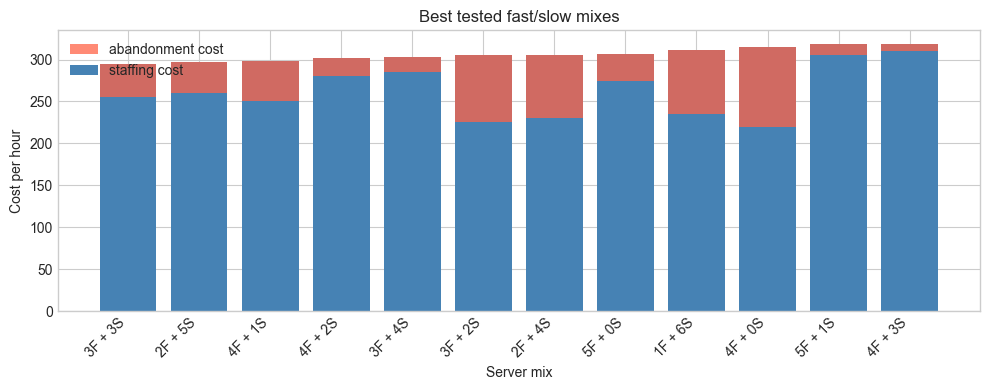

In [12]:
plot_df = mix_results.copy()
plot_df['mix'] = (
    plot_df['fast_servers'].astype(int).astype(str)
    + 'F + '
    + plot_df['slow_servers'].astype(int).astype(str)
    + 'S'
)

best_12 = plot_df.nsmallest(12, 'total_cost_rate').sort_values('total_cost_rate')

plt.figure(figsize=(10, 4))
plt.bar(best_12['mix'], best_12['total_cost_rate'], color='steelblue')
plt.bar(
    best_12['mix'],
    best_12['abandonment_cost_rate'],
    bottom=best_12['staffing_cost_rate'],
    color='tomato',
    alpha=0.75,
    label='abandonment cost',
)
plt.bar(best_12['mix'], best_12['staffing_cost_rate'], color='steelblue', label='staffing cost')
plt.xticks(rotation=45, ha='right')
plt.title('Best tested fast/slow mixes')
plt.xlabel('Server mix')
plt.ylabel('Cost per hour')
plt.legend()
plt.tight_layout()
plt.show()

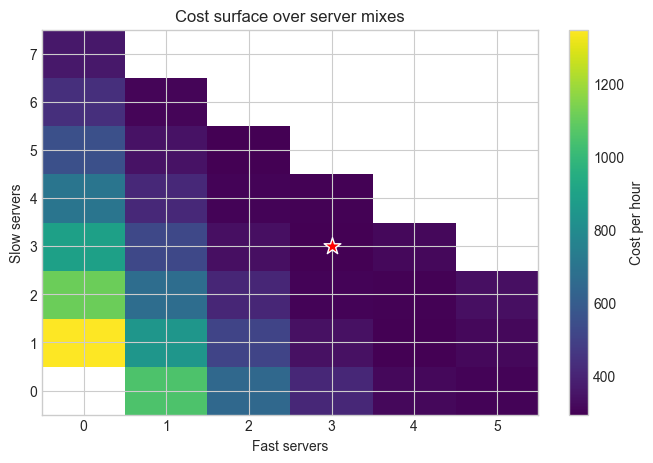

In [13]:
cost_grid = mix_results.pivot_table(
    index='slow_servers',
    columns='fast_servers',
    values='total_cost_rate',
)

plt.figure(figsize=(8, 5))
plt.imshow(cost_grid, origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label='Cost per hour')
plt.xticks(np.arange(len(cost_grid.columns)), cost_grid.columns.astype(int))
plt.yticks(np.arange(len(cost_grid.index)), cost_grid.index.astype(int))
plt.scatter(
    list(cost_grid.columns).index(best_mix['fast_servers']),
    list(cost_grid.index).index(best_mix['slow_servers']),
    s=160,
    marker='*',
    color='red',
    edgecolor='white',
)
plt.title('Cost surface over server mixes')
plt.xlabel('Fast servers')
plt.ylabel('Slow servers')
plt.show()

<div dir="rtl">

## פירוש התוצאה

### הפתרון הטוב ביותר לא ברור מראש בלי סימולציה.

### - יותר שרתים איטיים הם זולים, אבל לא בהכרח מפחיתים נטישות מספיק.
### - יותר שרתים מהירים מפחיתים נטישות, אבל עלות האיוש שלהם עולה מהר.
### - פתרון מעורב מאזן בין שני האפקטים.

### זו בדיוק החלטה שבה סימולציה עוזרת: העלות תלויה בדינמיקת התור, בסבלנות האקראית של הלקוחות, ובאינטראקציה בין שונות בזמני השירות לבין האיוש.

<div dir="rtl">

## חזרות: האם ההמלצה יציבה?

### ריצה אחת של סימולציה היא ניסוי אקראי אחד. עכשיו נחזור על כל תהליך החיפוש עם מימושים אקראיים חדשים, ונשווה את העלות הממוצעת של התמהילים.

In [16]:
def generate_two_type_inputs(seed, num_customers=800_000):
    rng = np.random.default_rng(seed)
    return {
        'inter_arrival_times': rng.exponential(scale=1 / ARRIVAL_RATE, size=num_customers),
        'slow_service_times': rng.exponential(
            scale=1 / SLOW_SERVICE_RATE,
            size=(num_customers, MAX_SLOW_SERVERS),
        ),
        'fast_service_times': rng.exponential(
            scale=1 / FAST_SERVICE_RATE,
            size=(num_customers, MAX_FAST_SERVERS),
        ),
        'patience_times': rng.gamma(shape=2.0, scale=0.08, size=num_customers),
    }

replication_rows = []

for replication in range(4):
    inputs = generate_two_type_inputs(seed=10_000 + replication)
    replication_result = evaluate_two_server_type_grid_with_abandonment(
        **inputs,
        slow_server_counts=range(MAX_SLOW_SERVERS + 1),
        fast_server_counts=range(MAX_FAST_SERVERS + 1),
        slow_server_cost_rate=SLOW_SERVER_COST_RATE,
        fast_server_cost_rate=FAST_SERVER_COST_RATE,
        abandonment_penalty=ABANDONMENT_PENALTY,
        max_total_servers=MAX_TOTAL_SERVERS,
    )
    replication_result['replication'] = replication
    replication_rows.append(replication_result)

replication_results = pd.concat(replication_rows, ignore_index=True)

replication_summary = (
    replication_results
    .groupby(['fast_servers', 'slow_servers', 'total_servers'], as_index=False)
    .agg(
        mean_total_cost_rate=('total_cost_rate', 'mean'),
        std_total_cost_rate=('total_cost_rate', 'std'),
        mean_fraction_abandoned=('fraction_abandoned', 'mean'),
        mean_throughput_rate=('throughput_rate', 'mean'),
    )
    .sort_values('mean_total_cost_rate')
)

replication_summary.head(12).round(4)

,fast_servers,slow_servers,total_servers,mean_total_cost_rate,std_total_cost_rate,mean_fraction_abandoned,mean_throughput_rate
23,3,3,6,293.7533,0.5555,0.0242,7.8040
19,2,5,7,295.9714,0.8944,0.0225,7.8179
26,4,1,5,297.5353,0.3448,0.0297,7.7602
27,4,2,6,301.4722,0.2348,0.0134,7.8905
24,3,4,7,302.5068,0.4186,0.0109,7.9103
18,2,4,6,303.5760,0.8296,0.0460,7.6299
22,3,2,5,304.1504,0.5471,0.0495,7.6021
29,5,0,5,306.6350,0.1699,0.0198,7.8397
13,1,6,7,311.0151,0.5472,0.0475,7.6177
25,4,0,4,315.5419,0.3056,0.0597,7.5201


In [17]:
top_replicated_mixes = replication_summary.head(3).copy()

print("Top mixes in this short replication check:")
for _, row in top_replicated_mixes.iterrows():
    print(
        f"{int(row['fast_servers'])} fast + {int(row['slow_servers'])} slow: "
        f"mean cost = {row['mean_total_cost_rate']:.2f}"
    )

print(
    "\nThe first two are close, so the important conclusion is the structure: "
    "a mixed fast/slow staffing plan is better than an all-fast or all-slow plan."
)

Top mixes in this short replication check:
3 fast + 3 slow: mean cost = 293.75
2 fast + 5 slow: mean cost = 295.97
4 fast + 1 slow: mean cost = 297.54

The first two are close, so the important conclusion is the structure: a mixed fast/slow staffing plan is better than an all-fast or all-slow plan.


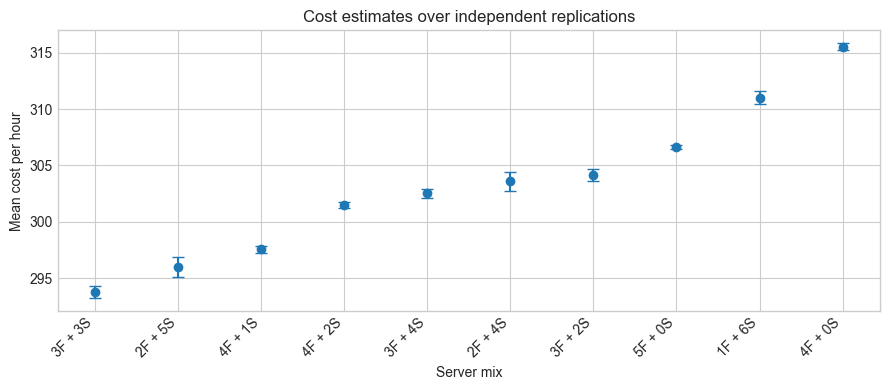

In [18]:
rep_plot = replication_summary.head(10).copy()
rep_plot['mix'] = (
    rep_plot['fast_servers'].astype(int).astype(str)
    + 'F + '
    + rep_plot['slow_servers'].astype(int).astype(str)
    + 'S'
)

plt.figure(figsize=(9, 4))
plt.errorbar(
    rep_plot['mix'],
    rep_plot['mean_total_cost_rate'],
    yerr=rep_plot['std_total_cost_rate'],
    fmt='o',
    capsize=4,
)
plt.xticks(rotation=45, ha='right')
plt.title('Cost estimates over independent replications')
plt.xlabel('Server mix')
plt.ylabel('Mean cost per hour')
plt.tight_layout()
plt.show()

<div dir="rtl">

### כפי שתוצאות נראות ישנו הבדל ברור בין הקבוצות.  

# ניתוחי רגישות:

### נניח כי יש שינוי בעלויות של השרתים או חישוב מחדש של עלות נטישה. 

### למשל כעת עלות שרת איטי הוא 30, אם זה יעלה ל-35, האם נצטרך לחשב את הסימולציה מחדש? 

### תשובה: לא.

### נסתכל על פונקציית המטרה: 

### $$C(f,s) = f \cdot C_F + s \cdot C_S + C_A \cdot A(f,s)$$



<div dir="rtl">


## $f \cdot C_F$ - לא תלוי בתוצאות הסימולציה

## $s \cdot C_S$ - לא תלוי בתוצאות הסימלוציה

## $C_A$ - לא תלוי בתוצאות הסימולציה

## $A(f,s)$- מספר נטשיות ליחידת זמן בממוצע. זה כן תלוי בערכי הסימולציה

### שינוי בכל ערך מלבד  $A(f,s)$ לא ידרוש מאיתנו הרבה נוספת רק צריך לקחת את הערכים מהסימולציה. 

### נחשב מחדש כאשר שרת איטי יותר יקר - במקום 30 עולה ל-35.

In [20]:
mix_results.head()

,fast_servers,slow_servers,total_servers,throughput_rate,abandonment_rate,fraction_abandoned,mean_waiting_time_served,fast_staffing_cost_rate,slow_staffing_cost_rate,staffing_cost_rate,abandonment_cost_rate,total_cost_rate,num_arrivals,num_served,num_abandoned
0,3,3,6,7.818759,0.199638,0.024897,0.003789,165.0,90.0,255.0,39.927606,294.927606,800000,780082,19918
1,2,5,7,7.831688,0.186708,0.023285,0.003483,110.0,150.0,260.0,37.341673,297.341673,800000,781372,18628
2,4,1,5,7.777541,0.240863,0.030039,0.004764,220.0,30.0,250.0,48.172568,298.172568,800000,775969,24031
3,4,2,6,7.909985,0.108419,0.013521,0.002303,220.0,60.0,280.0,21.683769,301.683769,800000,789183,10817
4,3,4,7,7.928801,0.089596,0.011174,0.001836,165.0,120.0,285.0,17.919112,302.919112,800000,791061,8939


In [33]:
SLOW_SERVER_COST_RATE_NEW = 35 
mix_results['new_total_cost'] = mix_results['slow_servers']*SLOW_SERVER_COST_RATE_NEW +  mix_results['fast_servers']*FAST_SERVER_COST_RATE + mix_results['abandonment_rate']*ABANDONMENT_PENALTY

In [35]:
mix_results.sort_values(by = 'new_total_cost').head()

,fast_servers,slow_servers,total_servers,throughput_rate,abandonment_rate,fraction_abandoned,mean_waiting_time_served,fast_staffing_cost_rate,slow_staffing_cost_rate,staffing_cost_rate,abandonment_cost_rate,total_cost_rate,num_arrivals,num_served,num_abandoned,new_total_cost
2,4,1,5,7.777541,0.240863,0.030039,0.004764,220.0,30.0,250.0,48.172568,298.172568,800000,775969,24031,303.172568
7,5,0,5,7.860672,0.157732,0.019671,0.003419,275.0,0.0,275.0,31.546407,306.546407,800000,784263,15737,306.546407
0,3,3,6,7.818759,0.199638,0.024897,0.003789,165.0,90.0,255.0,39.927606,294.927606,800000,780082,19918,309.927606
3,4,2,6,7.909985,0.108419,0.013521,0.002303,220.0,60.0,280.0,21.683769,301.683769,800000,789183,10817,311.683769
5,3,2,5,7.618622,0.399809,0.049861,0.007282,165.0,60.0,225.0,79.961797,304.961797,800000,760111,39889,314.961797


<div dir="rtl">

## קיבלנו תוצאה לא מפתיעה שהתייקרות שרת איטי הביא אותנו לכך ששרתים פחות אטרקטיביים.

### מה שחשוב ללמוד מזה אבל שיש שינויים שכופים עלינו לעשות סימלוציה מחדש - כל מה שנמצא בפונקציית מטרה שלנו ותלוי בתוצאה שלו וישנם ערכים שאמנם משנים את פונקציית המטרה אבל הם חיצוניים לסימולציה.
